In [1]:
import sys
import os
import pandas as pd
sys.path.append(os.path.abspath(".."))
from churn.modelo import dividir_datos, construir_modelo
from churn.datos import cargar_datos
from churn.eda import graficar_tasa
from churn.metricas import precision_at_k, lift_at_k, tabla_ganancias
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from lightgbm import LGBMClassifier
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression

In [2]:
df = cargar_datos("../data/dataset.csv")

In [3]:
X_train, X_test, y_train, y_test = dividir_datos(df)

In [4]:
num_cols = [
    "rev_Mean",         # Mean monthly revenue (charge amount)
    "mou_Mean",         # Mean number of monthly minutes of use
    "ovrrev_Mean",      # Mean overage revenue
    "comp_dat_Mean",    # Mean number of completed data calls
    "custcare_Mean",    # Mean number of customer care calls
    "phones",           # Number of handsets issued
    "months",           # Total number of months in service
    "eqpdays",          # Number of days (age) of current mobile phone
    "change_mou",       # Percentage change in monthly minutes of use vs previous three month average
    "change_rev",       # Percentage change in monthly revenue vs previous three month average
    "drop_vce_Mean",    # Mean number of dropped (failed) voice calls
    "drop_dat_Mean",    # Mean number of dropped (failed) data calls
    "drop_blk_Mean",    # Mean number of dropped or blocked calls
    "blck_vce_Mean",    # Mean number of blocked (failed) voice calls
    "blck_dat_Mean",    # Mean number of blocked (failed) data calls
    "unan_dat_Mean",    # Mean number of unanswered data calls
    "totmrc_Mean",      # Mean total monthly recurring charge
    "uniqsubs",         # Number of unique subscribers in the household
    "roam_Mean",        # Mean number of roaming calls
    "datovr_Mean",      # Mean revenue of data overage
    "da_Mean",          # Mean number of directory assisted calls
    "recv_sms_Mean",    # Mean number of received sms
    "callfwdv_Mean",    # Mean number of call forwarding calls
    "callwait_Mean",    # Mean number of call waiting calls
    "threeway_Mean",    # Mean number of three way calls
    "hnd_price",        # Current handset price
]

In [5]:
cat_cols = [
    "refurb_new",   # Handset: refurbished or new
    "infobase",     # InfoBase match
    "dualband",     # Dualband
    "asl_flag",     # Account spending limit
    "hnd_webcap",   # Handset web capability
]

In [6]:
def resumir_cv(tit_nombre: str, nombre: str, resultado: dict) -> dict:
    return {
        tit_nombre: nombre,
        "auc_train": resultado["train_score"].mean(),
        "auc_val": resultado["test_score"].mean(),
        "auc_val_std": resultado["test_score"].std(),
    }

filas = []
# pd.DataFrame(filas)

In [7]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [8]:
resultado_sin_limite = cross_validate(
    construir_modelo(num_cols, cat_cols, DecisionTreeClassifier()),
    X_train, y_train,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True,
    error_score="raise"
)

In [9]:
filas.append(resumir_cv("max_depth","None", resultado_sin_limite))

In [10]:
resultado_max_5 = cross_validate(
    construir_modelo(num_cols, cat_cols, DecisionTreeClassifier(max_depth=5)),
    X_train, y_train,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True,
    error_score="raise"
)

In [11]:
filas.append(resumir_cv("max_depth","5", resultado_max_5))

En la siguiente tabla se muestra como al no poner un límite de profundidad para el árbol de decisión, el modelo hace overfitting: El desempeño en train es perfecto (1.0) mientras que en validación es mucho más bajo (0.55), incluso peor que cuando se usó la regla de eqpdays (0.57). El modelo memoriza el ruido de train

Por otro lado, cuando se le agrega una profundidad máxima de 5, aunque supera lo que se obtuvo con Regresión Logística (tran = val = 0.61), sigue estando con uderfittng: el desempeño de train es bajo y la validación es también baja, parecido a train. El modelo es demasiado simple para el patrón

In [12]:
pd.DataFrame(filas)

,max_depth,auc_train,auc_val,auc_val_std
0,None,1.000000,0.548551,0.003872
1,5,0.639956,0.634456,0.002445


In [13]:
resultado_rand_forest_clf = cross_validate(
    construir_modelo(
        num_cols,cat_cols,
        RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=50,
            n_jobs=-1,
            random_state=42
        )
    ),
    X_train, y_train,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True,
    error_score="raise"
)

In [14]:
filas.clear()
filas.append(resumir_cv("modelo","RandomForestClassifier", resultado_rand_forest_clf))

In [15]:
resultado_lgbm_clf_imp = cross_validate(
    construir_modelo(
        num_cols,cat_cols,
        LGBMClassifier(
            random_state=42,
            verbose=-1
        )
    ),
    X_train, y_train,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True,
    error_score="raise"
)

In [16]:
filas.append(resumir_cv("modelo","LGBMClassifier (imputando)", resultado_lgbm_clf_imp))

In [17]:
resultado_lgbm_clf = cross_validate(
    construir_modelo(
        num_cols,cat_cols,
        LGBMClassifier(
            random_state=42,
            verbose=-1
        ),
        False
    ),
    X_train, y_train,
    cv=cv,
    scoring="roc_auc",
    return_train_score=True,
    error_score="raise"
)

In [18]:
filas.append(resumir_cv("modelo","LGBMClassifier (sin impotar)", resultado_lgbm_clf))

En la tabla de abajo se puede observar que el modelo que mejor desempeño tuvo fue LGBMClassifier sin imputar ni escalar variables numéricas. No mostró ni sobreaujuste ni subajuste: su val salió ~5 puntos debajo de train, lo cual no es suficiente para decir que hay sobreajuste.

Aquí quise hacer dos comparaciones para el mismo modelo de LGBMClassifier, una imputando y escalando y otra sin hacerlo. Observé que se comportó practicamente igual, eligo la versión más simple (sin imputar).

LightLGB, es un algoritmo basado en histogramas, diseñado para manejar datos dispersos y valores nulos de forma nativa.
Durante la fase de entrenamiento, cuando encuentra valores nulos en una variable, no falla. En su lugar, prueba temporalmente dos escenarios:
1. Enviar los nulos a la rama **izquierda**.
1. Enviar los nulos a la rama **derecha**.

El algoritmo calcula cuál de las dos opciones reduce más el error del modelo. Cuando el modelo ya está entrenado y recibe datos faltantes, direcciona esos datos hacia el lado por defecto que aprendió.

In [19]:
pd.DataFrame(filas)

,modelo,auc_train,auc_val,auc_val_std
0,RandomForestClassifier,0.738740,0.666932,0.003991
1,LGBMClassifier (imputando),0.737532,0.679870,0.002688
2,LGBMClassifier (sin impotar),0.738928,0.680010,0.002185


### Pruebas de hiperparámetros

In [20]:
cfg_1 = LGBMClassifier(random_state=42, subsample=0.8)

cfg_2 = LGBMClassifier(
    n_estimators=400,
    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=100,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=42
)

cfg_3 = LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.1,
    num_leaves=63,
    random_state=42,
    subsample=0.8
)

In [21]:
config_regularizada = LGBMClassifier(
    learning_rate= 0.05,   # Aprendizaje más lento
    n_estimators= 300, 
    num_leaves= 15,        # Árboles más "delgados" (menos nodos finales)
    max_depth= 5,          # Profundidad estricta
    min_child_samples= 50, # Exige al menos 50 datos para crear una nueva hoja
    subsample= 0.8,        # Usa solo el 80% de las filas por árbol (Bagging)
    colsample_bytree= 0.8, # Usa solo el 80% de las columnas por árbol
    reg_alpha= 0.1,        # Penalización L1 (Lasso)
    reg_lambda= 0.5,       # Penalización L2 (Ridge)
    random_state= 42
)

In [22]:
config_profunda = LGBMClassifier(
    learning_rate= 0.01,   # Aprendizaje muy lento
    n_estimators= 1000,    # Compensa el aprendizaje lento con muchos árboles
    num_leaves= 63,        # Permite árboles muy complejos
    max_depth= 8,          # Ligeramente profundo
    subsample= 0.9,
    colsample_bytree= 0.9,
    random_state= 42
)

In [23]:
config_dart = LGBMClassifier(
    boosting_type= 'dart', # Cambio radical en la construcción del ensamble
    learning_rate= 0.1,
    n_estimators= 200,
    drop_rate= 0.1,        # Probabilidad de apagar un árbol
    skip_drop= 0.5,        # Probabilidad de saltarse el proceso de dropout en una iteración
    max_drop= 50,          # Máximo de árboles apagados a la vez
    random_state= 42
)

In [24]:
configuraciones = {
    'default':      cfg_1, 
    'cfg_2':        cfg_2, 
    'cfg_3':        cfg_3, 
    'regularizada': config_regularizada, 
    'profunda':     config_profunda, 
    'dart':         config_dart
}

In [25]:
def resumir_cv(nombre: str, resultado: dict) -> dict:
    train = resultado["train_score"].mean()
    validacion = resultado["test_score"].mean()
    brecha = abs(train - validacion)
    return {
        'configuración': nombre,
        "train": train,
        "val": validacion,
        "brecha": brecha,
    }
# pd.DataFrame(filas)

In [26]:
filas.clear()

for cfg, estimador in configuraciones.items():
    resultado = cross_validate(
        construir_modelo(num_cols, cat_cols,estimador,False),
        X_train, y_train,
        cv=cv,
        scoring="roc_auc",
        return_train_score=True,
        error_score="raise"
    )
    filas.append(resumir_cv(cfg, resultado))

In [27]:
pd.DataFrame(filas)

,configuración,train,val,brecha
0,default,0.738928,0.680010,0.058918
1,cfg_2,0.728613,0.682820,0.045794
2,cfg_3,0.987739,0.661611,0.326128
3,regularizada,0.715042,0.680393,0.034650
4,profunda,0.778020,0.682799,0.095221
5,dart,0.714886,0.678919,0.035967


Se puede observar que de estas configuraciones la que más sobrejusta es cfg_3. Se nota porque el train es muy alto (0.99) y el val muy bajo (0.66).

Entre estos 6 modelos, el mejor es el de configuración regularizada. Esta configuración está pensada para restringir la complejidad del árbol y fuerza al modelo a aprender patrones más generales. Se puede ver que los valores de train y val no distan mucho uno del otro, apenas 3.4 puntos porcentuales siendo la brecha más corta, demostrando así que no hay riesgo de overfitting y superando aregresión logística en val (61%) por ~7 puntos.

### Evaluación final sobre el test

In [28]:
puntuacion_regla = X_test["eqpdays"].fillna(X_train["eqpdays"].median())

In [29]:
resultado_regresion =construir_modelo(
    num_cols, cat_cols,
    LogisticRegression(C=1.0, max_iter=2000)
).fit(X_train, y_train).predict_proba(X_test)

In [30]:
resultado_LightGBM = (
    construir_modelo(num_cols, cat_cols,config_regularizada,False)
    .fit(X_train, y_train)
    .predict_proba(X_test)
)

In [31]:
def armar_fila(nombre: str, y_true: list[int], scores: list[float]) -> dict:
    k_10 = int(0.10 * len(y_true))
    k_20 = int(0.20 * len(y_true))
    return {
        "Modelo": nombre,
        "AUC": f"{roc_auc_score(y_true, scores):.3}",
        "precision@10%": f"{precision_at_k(y_true, scores,k_10):.0%}",
        "lift@10%": f"{lift_at_k(y_true, scores,k_10):.3}",
        "precision@20%": f"{precision_at_k(y_true, scores,k_20):.0%}",
    }
# pd.DataFrame(filas)

In [32]:
filas_test_final = [
    armar_fila("Regla 'eqpdays'", y_test, puntuacion_regla),
    armar_fila("Logística", y_test, resultado_regresion[:, 1]),
    armar_fila("LightGBM", y_test, resultado_LightGBM[:, 1]),
]

pd.DataFrame(filas_test_final)

,Modelo,AUC,precision@10%,lift@10%,precision@20%
0,Regla 'eqpdays',0.571,58%,1.18,56%
1,Logística,0.607,64%,1.3,62%
2,LightGBM,0.68,78%,1.58,72%


In [33]:
tabla_ganancias = tabla_ganancias(y_test, resultado_LightGBM[:, 1])
tabla_ganancias

,n_clientes,churners,tasa_churn,score_promedio,lift,captura_acumulada
grupo,,,,,,
1,2000,1566,0.7830,0.740137,1.579903,0.157990
2,2000,1316,0.6580,0.644582,1.327684,0.290759
3,2000,1162,0.5810,0.596914,1.172316,0.407990
4,2000,1122,0.5610,0.559732,1.131961,0.521186
5,2000,1009,0.5045,0.527002,1.017958,0.622982
6,2000,996,0.4980,0.491669,1.004843,0.723467
7,2000,897,0.4485,0.451935,0.904964,0.813963
8,2000,819,0.4095,0.404450,0.826271,0.896590
9,2000,617,0.3085,0.330503,0.622478,0.958838


El score promedio se parece a tasa_churn en cada grupo

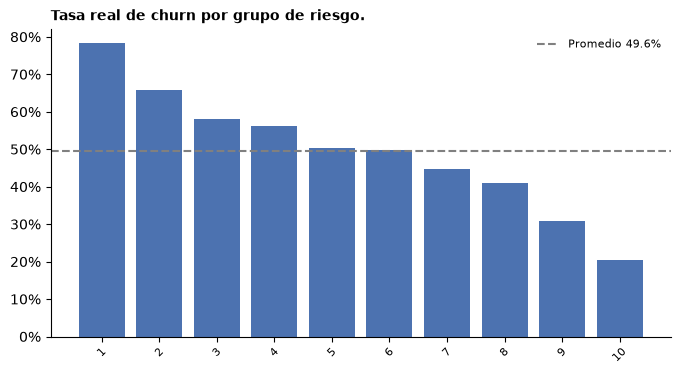

In [34]:
promedio = tabla_ganancias['tasa_churn'].mean()
fig = graficar_tasa(tabla_ganancias,"Tasa real de churn por grupo de riesgo.", promedio)

**Traducción de negocio:** Si contactamos al 10% de clientes con mayor riesgo, 78 de cada 100 realmente se iban, contra 50 si contactaramos al azar.

**Supuestos:** contactar a un cliente cuesta $10, una oferta retiene al 20% de de los que se iban, y un cliente retenido vale 6 meses de su rev_Mean.

In [35]:
df_test_clasificado = pd.DataFrame(X_test['rev_Mean'].copy().fillna(0))
df_test_clasificado['churn'] = y_test
df_test_clasificado['resultado_LightGBM'] = resultado_LightGBM[:,1]
df_test_clasificado = df_test_clasificado.sort_values(by='resultado_LightGBM', ascending=False)

In [36]:
pd.options.display.float_format = '{:,.2f}'.format

In [37]:
costo_contacto = 10
tasa_retencion = 0.20
meses_LTV = 6
filas_supuesto = []
n = len(df_test_clasificado)

for pct in range(10,110,10):
    k = int(n * (pct/100))
    df_pct = df_test_clasificado.copy().head(k)
    precision = precision_at_k(
        df_pct['churn'],
        df_pct['resultado_LightGBM'],
        k
    )
    rev_Mean = df_pct[df_pct['churn'] == 1]['rev_Mean'].mean()
    churners = df_pct['churn'].sum()
    costo_campana = float(costo_contacto * k)
    clientes_rescatados = churners * tasa_retencion
    ingreso_recuperado = clientes_rescatados*6*rev_Mean
    ganancia_marginal = ingreso_recuperado-costo_campana
    filas_supuesto.append({
        "Top": f"{pct}%",
        "n_clientes": k,
        "churners": churners,
        "precision": f"{precision:.0%}",
        "Costo ($)": -costo_campana,
        "Rescatados (20%)": clientes_rescatados,
        "Ingreso Recuperado ($)": ingreso_recuperado,
        "Ganancia Marginal ($)": ganancia_marginal
    })

df_resultados = pd.DataFrame(filas_supuesto)
df_resultados["Ganancia Incremental ($)"] = df_resultados["Ganancia Marginal ($)"].diff()
df_resultados

,Top,n_clientes,churners,precision,Costo ($),Rescatados (20%),Ingreso Recuperado ($),Ganancia Marginal ($),Ganancia Incremental ($)
0,10%,2000,1566,78%,"-20,000.00",313.20,"105,911.12","85,911.12",NaN
1,20%,4000,2882,72%,"-40,000.00",576.40,"196,311.38","156,311.38","70,400.26"
2,30%,6000,4044,67%,"-60,000.00",808.80,"271,941.20","211,941.20","55,629.81"
3,40%,8000,5166,65%,"-80,000.00","1,033.20","343,861.12","263,861.12","51,919.93"
4,50%,10000,6175,62%,"-100,000.00","1,235.00","408,102.81","308,102.81","44,241.69"
5,60%,12000,7171,60%,"-120,000.00","1,434.20","473,794.32","353,794.32","45,691.51"
6,70%,14000,8068,58%,"-140,000.00","1,613.60","535,115.74","395,115.74","41,321.42"
7,80%,16000,8887,56%,"-160,000.00","1,777.40","600,308.81","440,308.81","45,193.07"
8,90%,18000,9504,53%,"-180,000.00","1,900.80","655,606.28","475,606.28","35,297.47"
9,100%,20000,9912,50%,"-200,000.00","1,982.40","684,464.75","484,464.75","8,858.47"


En la tabla anterior se puede ver que mientras más clientes se contactan, mayor es la ganancia marginal. Esto sucede simplemente porque este análisis se hace sobre un dataset balanceado (tasa de churn promedio del 49.6%), algo que está fuera de la realidad. En una empresa de telco real en Europa, el porcentaje de churn suele ubicarse entre el 12% y el 15% anual. Con un conjunto real, en algún punto la ganancia marginal sería negativa y antes de ese punto habría que dejar de contactar a los clientes.

### Criterio de Parada: Maximización del ROI mediante Ganancia Incremental

Bajo los supuestos, consideré utilizar la ganancia incremental como criterio de parada para la campaña de de retención, en lugar de la ganancia marginal acumulada por las siguientes razones:
- Evita el enmascaramiento de pérdidas: Los grupos iniciales generan márgenes de ganancia altos que pueden subsidiar las pérdidas en deciles inferiores.
- Más allá de la ganancia márginal, contactar clientes consume capacidad coperativa, tiene que haber una importante diferencia de ganancia entre grupos para considerar invertir esfuerzos.
- Contactar innecesariamente a segmentos de muy bajo riesgo con ofertas de retención puede generar alertas indeseadas o acostumbrar a los clientes leales a esperar descuentos

**Conclusión:** Bajo los supuestos y este criterio, se debería limitar la campaña de retención al top 2.0%